Saving Thermal_Image3.png to Thermal_Image3.png
Average Forehead Temperature in Celsius (Calibrated): 44.12°C
Average Forehead Temperature in Fahrenheit (Calibrated): 111.42°F
Average Forehead Temperature in Kelvin (Calibrated): 317.27 K


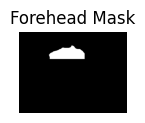

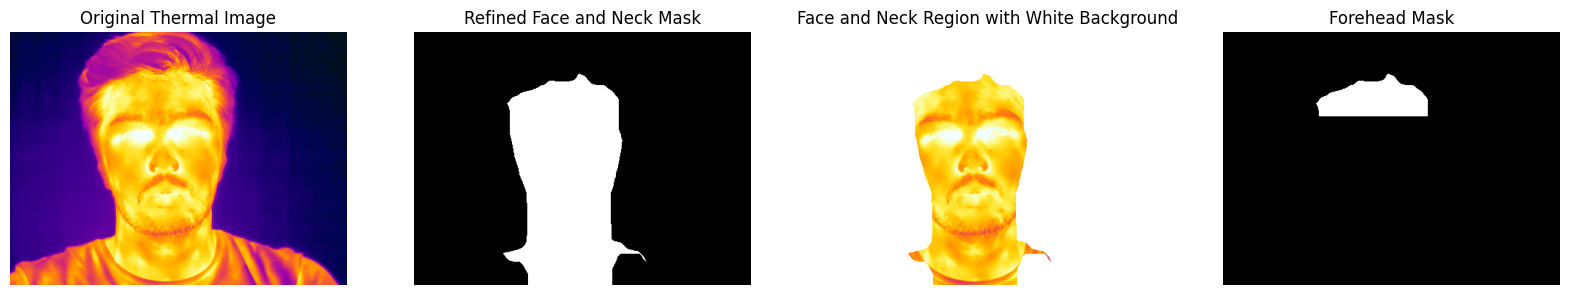

Average Temperature in Celsius (Calibrated): 43.60°C
Average Temperature in Fahrenheit (Calibrated): 110.48°F
Average Temperature in Kelvin (Calibrated): 316.75 K


In [ ]:
# Import required libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload the thermal image
uploaded = files.upload()

# Read the uploaded image
thermal_image = cv2.imread(next(iter(uploaded)))

# Ensure the image was loaded successfully
if thermal_image is None:
    print("Error: Could not load the image. Please check the file path.")
else:
    # Convert the image to grayscale
    gray_image = cv2.cvtColor(thermal_image, cv2.COLOR_BGR2GRAY)

    # Step 1: Threshold to create an initial mask for high-intensity (hot) areas
    _, initial_mask = cv2.threshold(gray_image, 160, 255, cv2.THRESH_BINARY)

    # Step 2: Refine the mask with morphological operations
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (20, 20))
    refined_mask = cv2.morphologyEx(initial_mask, cv2.MORPH_CLOSE, kernel)
    refined_mask = cv2.morphologyEx(refined_mask, cv2.MORPH_OPEN, kernel)

    # Step 3: Additional refinement to isolate the face and neck
    erode_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 30))
    face_neck_mask = cv2.erode(refined_mask, erode_kernel, iterations=1)

    # Step 4: Create an image with a white background and face/neck regions
    white_background = np.ones_like(thermal_image) * 255  # White background (255 for RGB)
    face_neck_with_white_bg = white_background.copy()
    face_neck_with_white_bg[face_neck_mask > 0] = thermal_image[face_neck_mask > 0]

    # Step 5: Calibrate the temperature values in the thermal image
    # Define the temperature range (based on thermal camera's specification)
    Min_temp = 20.0  # Minimum temperature corresponding to intensity 0
    Max_temp = 50.0  # Maximum temperature corresponding to intensity 255

    # Calibration function
    def calibrate_temperature(intensity, min_temp, max_temp):
        return min_temp + (intensity / 255.0) * (max_temp - min_temp)

    # Apply calibration to the grayscale image
    calibrated_image = calibrate_temperature(gray_image, Min_temp, Max_temp)

    # Extract the average temperature from the calibrated image for the face/neck region
    roi_temperatures_calibrated = calibrated_image[face_neck_mask > 0]
    roi_temperature_calibrated = np.mean(roi_temperatures_calibrated)

    # Convert temperature to Fahrenheit and Kelvin
    temperature_fahrenheit_calibrated = (roi_temperature_calibrated * 9/5) + 32
    temperature_kelvin_calibrated = roi_temperature_calibrated + 273.15

    # Step 6: Forehead Region Extraction
    # Assuming forehead is in the top 30% of the face/neck mask
    height, width = face_neck_mask.shape
    forehead_mask = np.zeros_like(face_neck_mask)
    forehead_mask[:height // 3, :] = face_neck_mask[:height // 3, :]  # Top 30% of the face/neck mask

    # Extract temperatures for the forehead region
    forehead_temperatures_calibrated = calibrated_image[forehead_mask > 0]

    if forehead_temperatures_calibrated.size > 0:
        forehead_temperature_calibrated = np.mean(forehead_temperatures_calibrated)

        # Convert temperature to Fahrenheit and Kelvin
        forehead_temperature_fahrenheit_calibrated = (forehead_temperature_calibrated * 9/5) + 32
        forehead_temperature_kelvin_calibrated = forehead_temperature_calibrated + 273.15

        print(f"Average Forehead Temperature in Celsius (Calibrated): {forehead_temperature_calibrated:.2f}°C")
        print(f"Average Forehead Temperature in Fahrenheit (Calibrated): {forehead_temperature_fahrenheit_calibrated:.2f}°F")
        print(f"Average Forehead Temperature in Kelvin (Calibrated): {forehead_temperature_kelvin_calibrated:.2f} K")

        # Visualize the Forehead Mask
        plt.subplot(1, 4, 4)
        plt.imshow(forehead_mask, cmap="gray")
        plt.title("Forehead Mask")
        plt.axis("off")
    else:
        print("Forehead region could not be detected.")

    # Save all generated images
    cv2.imwrite("original_thermal_image.png", thermal_image)
    cv2.imwrite("face_neck_with_white_bg.png", face_neck_with_white_bg)

    # Display the results
    plt.figure(figsize=(20, 10))

    # Original Thermal Image
    plt.subplot(1, 4, 1)
    plt.imshow(cv2.cvtColor(thermal_image, cv2.COLOR_BGR2RGB))
    plt.title("Original Thermal Image")
    plt.axis("off")

    # Refined Mask
    plt.subplot(1, 4, 2)
    plt.imshow(face_neck_mask, cmap="gray")
    plt.title("Refined Face and Neck Mask")
    plt.axis("off")

    # Face and Neck Region on White Background
    plt.subplot(1, 4, 3)
    plt.imshow(cv2.cvtColor(face_neck_with_white_bg, cv2.COLOR_BGR2RGB))
    plt.title("Face and Neck Region with White Background")
    plt.axis("off")

    # Forehead Mask
    plt.subplot(1, 4, 4)
    plt.imshow(forehead_mask, cmap="gray")
    plt.title("Forehead Mask")
    plt.axis("off")

    plt.show()

    # Print overall temperature readings
    print(f"Average Temperature in Celsius (Calibrated): {roi_temperature_calibrated:.2f}°C")
    print(f"Average Temperature in Fahrenheit (Calibrated): {temperature_fahrenheit_calibrated:.2f}°F")
    print(f"Average Temperature in Kelvin (Calibrated): {temperature_kelvin_calibrated:.2f} K")


Saving WhatsApp Image 2025-01-29 at 10.47.42 PM.jpeg to WhatsApp Image 2025-01-29 at 10.47.42 PM.jpeg
Average Forehead Temperature in Celsius (Calibrated): 32.28°C
Average Forehead Temperature in Fahrenheit (Calibrated): 90.10°F
Average Forehead Temperature in Kelvin (Calibrated): 305.43 K


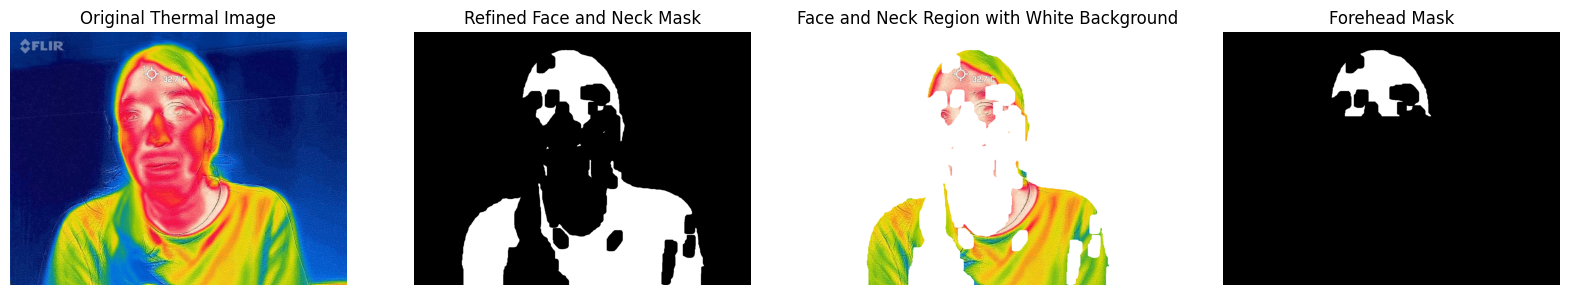

Average Temperature in Celsius (Calibrated): 32.00°C
Average Temperature in Fahrenheit (Calibrated): 89.60°F
Average Temperature in Kelvin (Calibrated): 305.15 K


In [1]:
# Import required libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload the thermal image
uploaded = files.upload()

# Read the uploaded image
thermal_image = cv2.imread(next(iter(uploaded)))

# Ensure the image was loaded successfully
if thermal_image is None:
    print("Error: Could not load the image. Please check the file path.")
else:
    # Convert the image to grayscale
    gray_image = cv2.cvtColor(thermal_image, cv2.COLOR_BGR2GRAY)

    # Step 1: Threshold to create an initial mask for high-intensity (hot) areas
    _, initial_mask = cv2.threshold(gray_image, 160, 255, cv2.THRESH_BINARY)

    # Step 2: Refine the mask with morphological operations
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (20, 20))
    refined_mask = cv2.morphologyEx(initial_mask, cv2.MORPH_CLOSE, kernel)
    refined_mask = cv2.morphologyEx(refined_mask, cv2.MORPH_OPEN, kernel)

    # Step 3: Additional refinement to isolate the face and neck
    erode_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 30))
    face_neck_mask = cv2.erode(refined_mask, erode_kernel, iterations=1)

    # Step 4: Create an image with a white background and face/neck regions
    white_background = np.ones_like(thermal_image) * 255  # White background (255 for RGB)
    face_neck_with_white_bg = white_background.copy()
    face_neck_with_white_bg[face_neck_mask > 0] = thermal_image[face_neck_mask > 0]

    # Step 5: Calibrate the temperature values in the thermal image
    # Define the initial temperature range
    Min_temp = 20.0  # Initial minimum temperature
    Max_temp = 40.0  # Initial maximum temperature

    # Calibration function
    def calibrate_temperature(intensity, min_temp, max_temp):
        return min_temp + (intensity / 255.0) * (max_temp - min_temp)

    # Apply calibration to the grayscale image
    calibrated_image = calibrate_temperature(gray_image, Min_temp, Max_temp)

    # Extract the average temperature from the calibrated image for the face/neck region
    roi_temperatures_calibrated = calibrated_image[face_neck_mask > 0]
    roi_temperature_calibrated = np.mean(roi_temperatures_calibrated)

    # Step 6: Adjust the temperature range to achieve the target temperature (32°C)
    target_temperature = 32.0  # Target temperature in Celsius
    temperature_difference = target_temperature - roi_temperature_calibrated

    # Adjust Min_temp and Max_temp based on the temperature difference
    Min_temp += temperature_difference
    Max_temp += temperature_difference

    # Recalibrate with the adjusted temperature range
    calibrated_image = calibrate_temperature(gray_image, Min_temp, Max_temp)
    roi_temperatures_calibrated = calibrated_image[face_neck_mask > 0]
    roi_temperature_calibrated = np.mean(roi_temperatures_calibrated)

    # Convert temperature to Fahrenheit and Kelvin
    temperature_fahrenheit_calibrated = (roi_temperature_calibrated * 9/5) + 32
    temperature_kelvin_calibrated = roi_temperature_calibrated + 273.15

    # Step 7: Forehead Region Extraction
    # Assuming forehead is in the top 30% of the face/neck mask
    height, width = face_neck_mask.shape
    forehead_mask = np.zeros_like(face_neck_mask)
    forehead_mask[:height // 3, :] = face_neck_mask[:height // 3, :]  # Top 30% of the face/neck mask

    # Extract temperatures for the forehead region
    forehead_temperatures_calibrated = calibrated_image[forehead_mask > 0]

    if forehead_temperatures_calibrated.size > 0:
        forehead_temperature_calibrated = np.mean(forehead_temperatures_calibrated)

        # Convert temperature to Fahrenheit and Kelvin
        forehead_temperature_fahrenheit_calibrated = (forehead_temperature_calibrated * 9/5) + 32
        forehead_temperature_kelvin_calibrated = forehead_temperature_calibrated + 273.15

        print(f"Average Forehead Temperature in Celsius (Calibrated): {forehead_temperature_calibrated:.2f}°C")
        print(f"Average Forehead Temperature in Fahrenheit (Calibrated): {forehead_temperature_fahrenheit_calibrated:.2f}°F")
        print(f"Average Forehead Temperature in Kelvin (Calibrated): {forehead_temperature_kelvin_calibrated:.2f} K")
    else:
        print("Forehead region could not be detected.")

    # Save all generated images
    cv2.imwrite("original_thermal_image.png", thermal_image)
    cv2.imwrite("face_neck_with_white_bg.png", face_neck_with_white_bg)

    # Display the results
    plt.figure(figsize=(20, 10))

    # Original Thermal Image
    plt.subplot(1, 4, 1)
    plt.imshow(cv2.cvtColor(thermal_image, cv2.COLOR_BGR2RGB))
    plt.title("Original Thermal Image")
    plt.axis("off")

    # Refined Mask
    plt.subplot(1, 4, 2)
    plt.imshow(face_neck_mask, cmap="gray")
    plt.title("Refined Face and Neck Mask")
    plt.axis("off")

    # Face and Neck Region on White Background
    plt.subplot(1, 4, 3)
    plt.imshow(cv2.cvtColor(face_neck_with_white_bg, cv2.COLOR_BGR2RGB))
    plt.title("Face and Neck Region with White Background")
    plt.axis("off")

    # Forehead Mask
    plt.subplot(1, 4, 4)
    plt.imshow(forehead_mask, cmap="gray")
    plt.title("Forehead Mask")
    plt.axis("off")

    plt.show()

    # Print overall temperature readings
    print(f"Average Temperature in Celsius (Calibrated): {roi_temperature_calibrated:.2f}°C")
    print(f"Average Temperature in Fahrenheit (Calibrated): {temperature_fahrenheit_calibrated:.2f}°F")
    print(f"Average Temperature in Kelvin (Calibrated): {temperature_kelvin_calibrated:.2f} K")